In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# 1. Import a built-in regression dataset (California Housing or Diabetes)
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load data
housing = fetch_california_housing(as_frame=True)
df_ml = housing.frame

# Let's take a small subset for easy visualization (e.g., predicting House Value based on Median Income)
X = df_ml[['MedInc']]  # Feature (Independent variable)
y = df_ml['MedHouseVal'] # Target (Dependent variable)

In [7]:
# 2. Split data into Training set (80%) and Testing set (20%)
# This prevents the model from "cheating" by memorizing the answers.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
# 3. Initialize and Train the Model
model = LinearRegression()
model.fit(X_train, y_train) # The model learns the relationship here!

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.42]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['MedInc']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.4446
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [9]:
# 4. Make Predictions on the Test set
y_pred = model.predict(X_test)

In [10]:
# 5. Evaluate the Model (Math in action!)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Machine Learning Model Results ---")
print(f"Learned Coefficient (Slope): {model.coef_[0]:.4f}")
print(f"Learned Intercept: {model.intercept_:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-Squared (Accuracy Score): {r2:.4f}")

--- Machine Learning Model Results ---
Learned Coefficient (Slope): 0.4193
Learned Intercept: 0.4446
Mean Squared Error (MSE): 0.7091
R-Squared (Accuracy Score): 0.4589


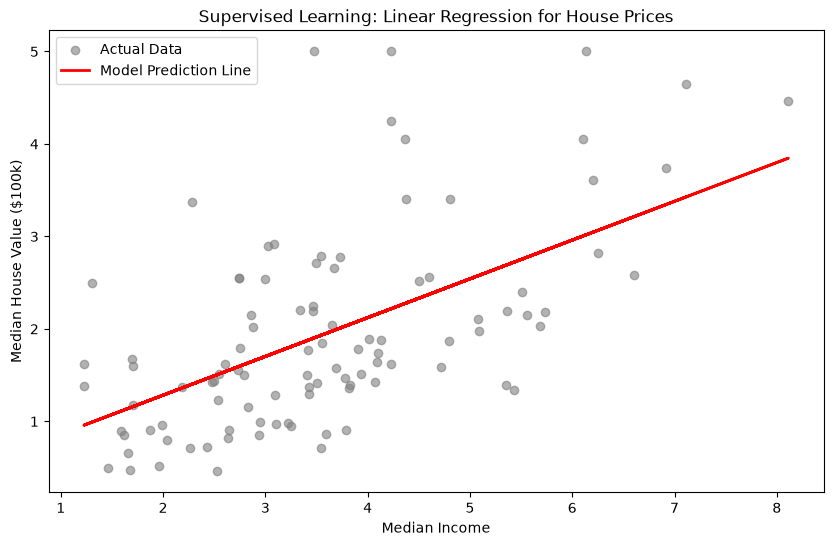

In [11]:
plt.figure(figsize=(10, 6))
# Plot actual test data points (sample a few so the plot isn't too crowded)
plt.scatter(X_test[:100], y_test[:100], color='gray', alpha=0.6, label='Actual Data')

# Plot the model's regression line
plt.plot(X_test[:100], y_pred[:100], color='red', linewidth=2, label='Model Prediction Line')

plt.title('Supervised Learning: Linear Regression for House Prices')
plt.xlabel('Median Income')
plt.ylabel('Median House Value ($100k)')
plt.legend()
plt.show()